# 2D Spectrograph Calibration

Often, the output from a spectrograph is shone onto a CCD. This is often used to take the spectra of many sources at once, or simply for convenience (CCD's are cheap and availiable). The result is that each pixel on the CCD corresponds to a wavelength in the image. Determining the mapping is what we mean when we say we are 'calibrating the spectrograph'. We can think about this problem as trying to determine a multivariable function that takes pixel locations and turns them into a wavelength (the 2D analog to what we did in the 1D case):

$$
\lambda = f(x,y)
$$

Where $\lambda$ is the wavelength, $(x,y)$ is the co-ordinate of our CCD pixel, and $f$ is our calibration function. In order to find the function, $f$, we will need a calibration source.

In [4]:
"""
IMPORTS
"""
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from matplotlib.colors import LogNorm
from scipy.optimize import curve_fit

In this case, our calibration source is a neon lamp. Neon has many transition lines that we can use to get a **discrete sampling** of $\lambda$. We can then propose a model for our calibration function and perform a least squares fit. Let's start by looking at our calibration source:

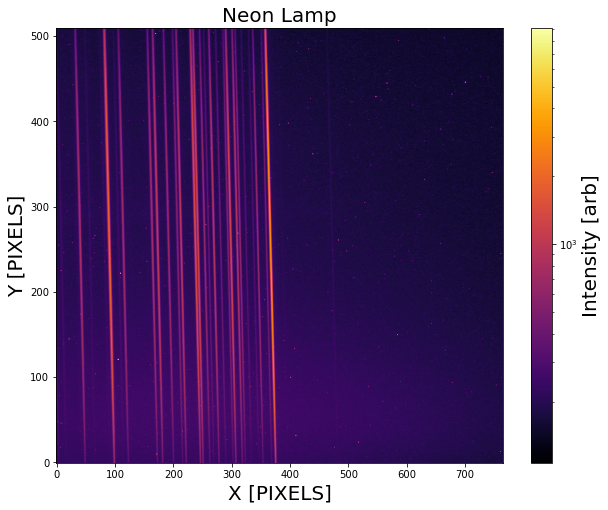

In [5]:
#The file name
fits_image_filename = 'Neon_int120.fit'
#fits_image_filename = 'moon_int60s.fit'

#Opening the fits file and extracting the image as a numpy array
neon = fits.open(fits_image_filename)[0].data

#Now let's plot it up to see what we are working with
plt.figure(figsize=(10,8))
plt.imshow(neon, 
           cmap = 'inferno', 
           aspect='auto', 
           norm = LogNorm(vmin=np.min(neon), 
                          vmax=np.max(neon)),
           origin = 'lower')
plt.xlabel("X [PIXELS]", size = 20)
plt.ylabel("Y [PIXELS]", size = 20)
plt.title("Neon Lamp", size = 20)
cb = plt.colorbar()
cb.set_label(label='Intensity [arb]', size=20)
plt.show()

So what we see is that the X-axis is analogous to our typical 1D spectrograph from earlier in the lab and the Y-axis is a roughly linear extension into the second dimension. For this excercise, I am going to assume that you already have a function that can calibrate ANY 1D SLICE of an image like the one above. If you don't have a function that does that, you should work on it. It will be important that you have an automated way of assigning each of the peaks from a 1D slice to its associated theoretical wavelength. I will give you a little bit of insight into how you might do that.

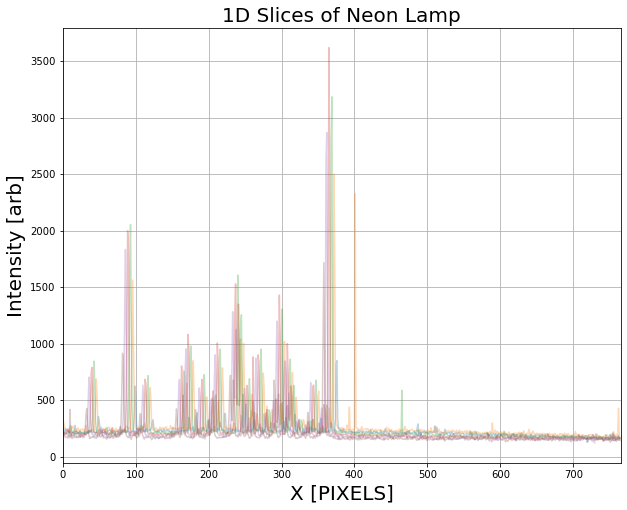

In [6]:
#We can also plot every 5 rows or so on top of each other like this
plt.figure(figsize=(10,8))
for i in np.arange(neon.shape[0])[::100]:
    plt.plot(neon[i, :], alpha = 0.3)
plt.xlabel("X [PIXELS]", size = 20)
plt.ylabel("Intensity [arb]", size = 20)
plt.title("1D Slices of Neon Lamp", size = 20)
plt.grid()
plt.xlim(0, neon.shape[1])
plt.show()

-0.03529411764705882


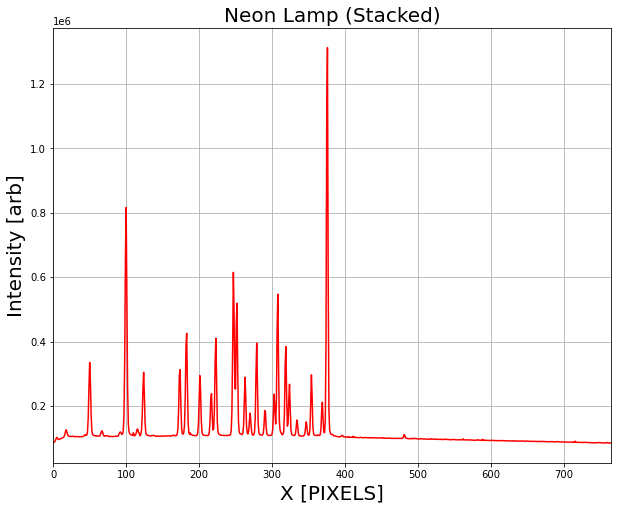

In [7]:
"""
We can even stack all of the rows on top of each other to get 
a better idea of the overall spectrum

Lets start by computing the slope. Since the max pixel is usually 
from the dominant emission line, lets try using the max value of
the first and last rows as our reference.

Then we can shift each row using the numpy.roll function (see the docs)
to roughly line all of the rows up (to pixel precision) and stack them.
"""
starting_max = np.where(neon[0, :] == np.max(neon[0, :]))[0]
ending_max = np.where(neon[-1, :] == np.max(neon[-1, :]))[0]
slope = ((ending_max - starting_max)/neon.shape[0])[0]
print(slope)
stack_neon = np.zeros(neon.shape[1])
for i in range(neon.shape[0]):
    stack_neon += np.roll(neon[i, :], round(-1*slope*i))
    
plt.figure(figsize=(10,8))
plt.plot(stack_neon, color = 'r', alpha = 1)
plt.xlabel("X [PIXELS]", size = 20)
plt.ylabel("Intensity [arb]", size = 20)
plt.title("Neon Lamp (Stacked)", size = 20)
plt.grid()
plt.xlim(0, neon.shape[1])
plt.show()

We can compare our stacked spectrum to a neon spectrum we find online to extract the theoretical wavelength of each peak. How well do they compare? We can use the brightest (or most obvious) lines to get an approximate solution, then we can use our approximate solution to disentangle all of the more complicated lines. With a few iterations, we should get pretty good result.

![title](neon_2.gif)


The next step in the process is fitting. To illustrate how you can fit 2D spectrograph data, I am going to create mock data using a fake calibration function. 

In [8]:
#Here is my fake calibration function 
SLANT = 0.03
def calibration(x,y, s = 0.03):
    return -(x+500)**0.9+1000 - s*y 

#Here I am just evaluating an analogous grid to the CCD image
#at the calibration function
x = np.arange(neon.shape[1])
y = np.arange(neon.shape[0])

#Just an easy way of going about evaluating a 2D function,
#No need to be super fancy
calibration2D = np.empty((y.size,x.size))
for i in range(x.size):
    for j in range(y.size):
        calibration2D[j,i] = calibration(x[i],y[j], s = SLANT)

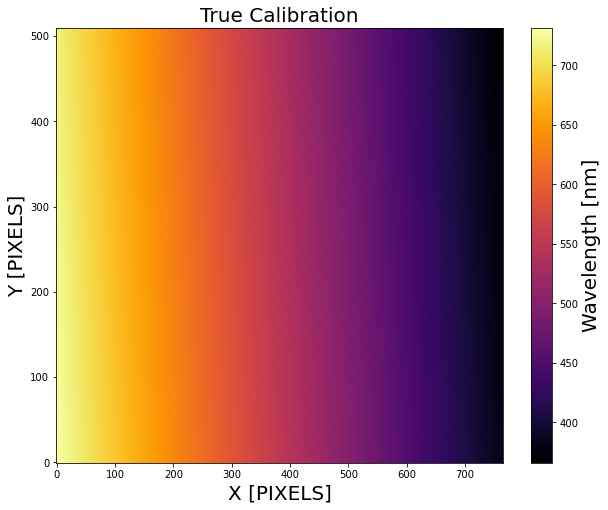

In [9]:
#And now I can plot it to see what it looks like
plt.figure(figsize=(10,8))
plt.imshow(calibration2D, cmap = 'inferno', aspect = 'auto', origin = 'lower')
plt.xlabel("X [PIXELS]", size = 20)
plt.ylabel("Y [PIXELS]", size = 20)
plt.title("True Calibration", size = 20)
cb = plt.colorbar()
cb.set_label(label='Wavelength [nm]', size=20)
plt.show()

Can you see the diagonal line of constant wavelength? No? Now let's make some fake emission line data.

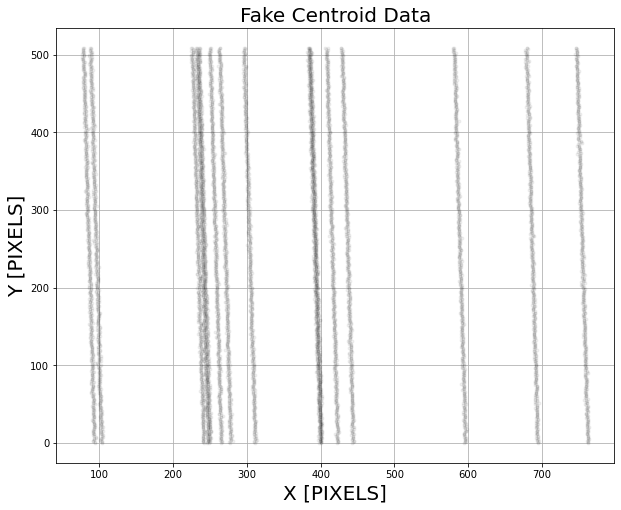

In [10]:
#I am going to sample 10 data points from the 'first row'
NUM_DATA_POINTS = 15
NOISE = 0 #units of nm
first_row_x = np.random.choice(x, size = NUM_DATA_POINTS)

"""
Now I am going to use the known slant from my calibration function
to get x and y values of 'centroids', analogous to want you would have 
from centroiding emission lines from the neon source.

Again, I am not doing this in the most efficient way possible.
"""
centroid_xs = np.empty((NUM_DATA_POINTS, y.size))
centroid_ys = np.empty((NUM_DATA_POINTS, y.size))
for i in range(y.size):
    centroid_xs[:,i] = first_row_x - SLANT*i
    centroid_ys[:,i] = np.zeros(NUM_DATA_POINTS) + i
    
#Flatten the centroid arrays so they are essentially a 'list of co-ordinates'
centroid_xs = centroid_xs.flatten()
centroid_ys = centroid_ys.flatten()

centroid_xs += np.random.normal(0,1,centroid_xs.size).reshape(centroid_xs.shape)
# centroid_ys += np.random.normal(0,1,centroid_ys.size).reshape(centroid_ys.shape)

"""
Use the known calibration to get the wavelength solution.
These values would be what you get from the theoretical emission
lines of neon (see above)
"""
wavelengths = calibration(centroid_xs, centroid_ys, s = SLANT) + np.random.normal(0, NOISE, size = centroid_xs.size)

#Plot the fake emission lines
plt.figure(figsize=(10,8))
plt.plot(centroid_xs, centroid_ys, '.', color = 'k', alpha = 0.05)
plt.xlabel("X [PIXELS]", size = 20)
plt.ylabel("Y [PIXELS]", size = 20)
plt.title("Fake Centroid Data", size = 20)
plt.grid()
plt.show()

[-1.07343425e-08  3.89063885e-05 -4.81804629e-01  4.79233075e-10
 -3.00008297e-02  7.31330710e+02]
[[ 1.31980621e-22 -1.59049240e-19  5.28753354e-17  5.84548672e-23
   8.56475568e-20 -4.56699349e-15]
 [-1.59049240e-19  1.95439687e-16 -6.68720967e-14 -1.03086276e-19
  -9.96870297e-17  6.01656754e-12]
 [ 5.28753354e-17 -6.68720967e-14  2.39828913e-11  4.40598504e-17
   3.96517747e-14 -2.31894544e-09]
 [ 5.84548672e-23 -1.03086276e-19  4.40598504e-17  1.42345025e-17
  -7.24322117e-15  6.09171052e-13]
 [ 8.56475568e-20 -9.96870297e-17  3.96517747e-14 -7.24322117e-15
   3.95649730e-12 -3.86396953e-10]
 [-4.56699349e-15  6.01656754e-12 -2.31894544e-09  6.09171052e-13
  -3.86396953e-10  2.99898499e-07]]


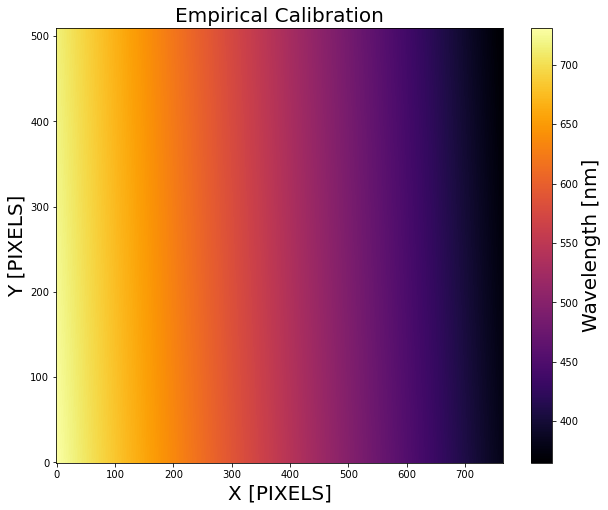

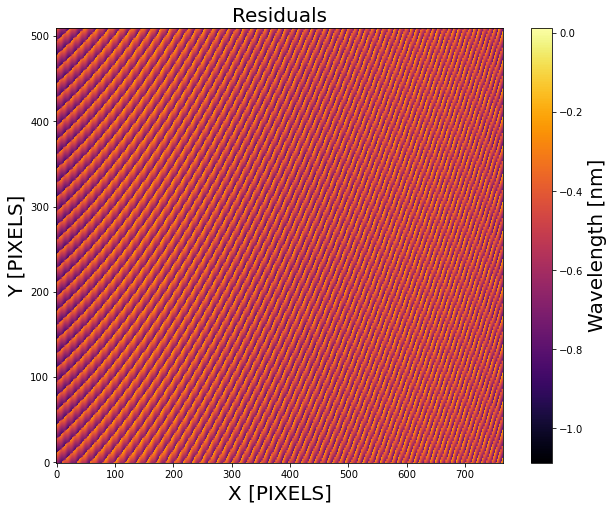

In [14]:
"""
Now that I have my fake data, I can fit a model to it

I have chosen a cubic model along the x-axis and a linear in the y axis.

You should choose your model very carefully. We talked about how to choose
a good model and how to chedk if you are overfitting in the tutorial
on 1D fitting. Go back and re-visit that tutorial if you need help with that.
You should always try to justify your choice of model.
"""
def model(x, a, b, c, d, e, f):

    return a*x[0,:]**3 + b*x[0,:]**2 + c*x[0,:] + d*x[1,:]**2 + e*x[1,:] + f

def model1D(x, a, b, c, d, e, f):

    return  a*x[0]**3 + b*x[0]**2 + c*x[0] + d*x[1]**2 + e*x[1] + f

#I stacked the centroid co-ordinates to get them ready for curve_fit
centroids = np.vstack((centroid_xs, centroid_ys))

popt, pcov = curve_fit(model, centroids, wavelengths)
print(popt)
print(pcov)

fitted_calibration = np.empty_like(neon)
for i in range(x.size):
    for j in range(y.size):
        fitted_calibration[j,i] = model1D([x[i], y[j]], *popt)
    
plt.figure(figsize=(10,8))
plt.imshow(fitted_calibration, cmap = 'inferno', aspect = 'auto', origin = 'lower')
plt.xlabel("X [PIXELS]", size = 20)
plt.ylabel("Y [PIXELS]", size = 20)
plt.title("Empirical Calibration", size = 20)
cb = plt.colorbar()
cb.set_label(label='Wavelength [nm]', size=20)
plt.show()

plt.figure(figsize=(10,8))
plt.imshow(fitted_calibration - calibration2D, cmap = 'inferno', aspect = 'auto', origin = 'lower')
plt.xlabel("X [PIXELS]", size = 20)
plt.ylabel("Y [PIXELS]", size = 20)
plt.title("Residuals", size = 20)
cb = plt.colorbar()
cb.set_label(label='Wavelength [nm]', size=20)
plt.show()

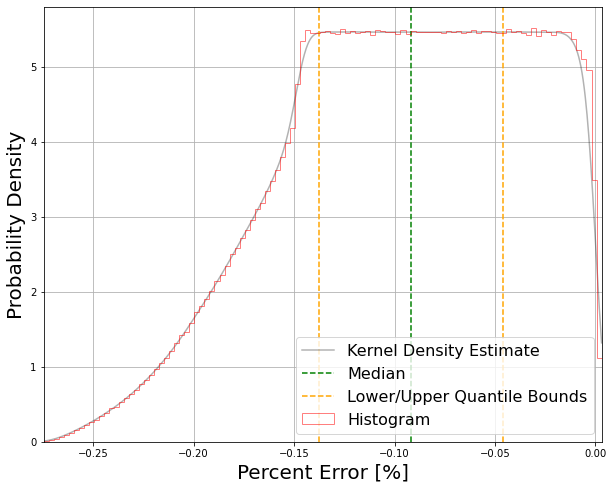

In [12]:
from sklearn.neighbors import KernelDensity

#Compute the percent error, and print the statistics
percent_err = 100*(fitted_calibration - calibration2D)/calibration2D
percent_err = percent_err.flatten()
domain = np.linspace(percent_err.min(), percent_err.max(), 1000)
std = np.std(percent_err)
lower_quantile = np.percentile(percent_err, 25)
median = np.median(percent_err)
upper_quantile = np.percentile(percent_err, 75)
IQR = upper_quantile - lower_quantile

bw = 0.9*min(std, IQR/1.34)*percent_err.size**(-1/5)
kernel_type = 'gaussian'

# # instantiate and fit the KDE model
kde = KernelDensity(bandwidth = bw, kernel = kernel_type)
kde.fit(percent_err[:, None])

# # score_samples returns the log of the probability density
logprob = kde.score_samples(domain[:, None])

plt.figure(figsize=(10,8))
plt.plot(domain, np.exp(logprob), color = 'k', alpha = 0.3, label = 'Kernel Density Estimate')
plt.axvline(x = median, color = 'green', label = 'Median', linestyle = '--')
plt.axvline(x = upper_quantile, color = 'orange', label = 'Lower/Upper Quantile Bounds', linestyle = '--')
plt.axvline(x = lower_quantile, color = 'orange', linestyle = '--')
plt.hist(percent_err, bins = 'fd', density= True, color = 'r', histtype = 'step', label = 'Histogram', alpha = 0.5)
plt.grid()
plt.xlabel("Percent Error [%]", size = 20)
plt.ylabel("Probability Density", size = 20)
plt.legend(prop = {'size': 16}, loc = 'best')
plt.xlim(percent_err.min(), percent_err.max())
plt.show()